# 04 · SARIMAX con variables exógenas (tarea A7)

**Fase CRISP-DM:** modelado y evaluación. SARIMAX sobre `log1p(y)` con promoción, apertura, festivos,
Promo2 y términos de Fourier. **Nunca usa `Customers`.** En validación y prueba las exógenas son las
reales del periodo, bajo el supuesto de que el calendario de promociones, aperturas y festivos se
conoce de antemano.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import *
from src.features.exog import load_history

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.float_format", "{:,.3f}".format, "display.width", 160)
history = load_history()
LEVELS = ["total", *LEVELS_TYPES]

import json
from statsmodels.stats.diagnostic import acorr_ljungbox
from src.models.arima import SELECTION_FILE, GRID_FILE, ROLLING_FILE, Spec, USES_EXOG, fit_model, level_data, training_target
warnings.filterwarnings("ignore")
ALL_LEVELS = ["total", *LEVELS_TYPES, *[f"store_{n}" for n in SELECTED_STORES]]
sel = json.loads(SELECTION_FILE.read_text("utf-8"))["levels"]
grid = pd.read_csv(GRID_FILE)
def metricas(modelo):
    return json.loads((ARTIFACTS / "metrics" / f"{modelo}.json").read_text("utf-8"))["levels"]
def spec(uid, modelo):
    c = sel[uid][modelo]; return Spec(tuple(c["order"]), tuple(c["seasonal_order"]))
def ajustar(uid, modelo, corte):
    y, x = level_data(history, uid); y = y.loc[:corte]
    return fit_model(training_target(y, x), x.loc[:corte] if USES_EXOG[modelo] else None, spec(uid, modelo))
def ljung(res, lags=(7, 14, 28)):
    r = pd.Series(res.resid).iloc[max(res.loglikelihood_burn, 14):].dropna()
    t = acorr_ljungbox(r, lags=list(lags)); return t["lb_pvalue"].to_dict()
def comparar(split):
    n, a, b = metricas("naive"), metricas("sarima"), metricas("sarimax")
    return pd.DataFrame([{"nivel": u, **{f"{m} {k}": d[u][split][k] for m, d in [("naive", n), ("sarima", a), ("sarimax", b)] for k in ("rmse", "mape")}} for u in ALL_LEVELS]).set_index("nivel")

from statsmodels.iolib.smpickle import load_pickle
from src.features.exog import build_future_exog

## 1. Órdenes elegidos

In [2]:
g = grid[grid["model"] == "sarimax"]
filas = []
for u in ALL_LEVELS:
    c = sel[u]["sarimax"]; a = g[(g.unique_id == u) & (g.source == "auto_arima")].iloc[0]
    filas.append({"nivel": u, "elegido": f"{tuple(c['order'])}{tuple(c['seasonal_order'][:3])}", "origen": c["source"], "RMSE val": c["rmse"], "MAPE val": c["mape"],
                  "AutoARIMA": f"{a['order']}{a['seasonal_order']}", "RMSE val AutoARIMA": a["rmse"], "MAPE val AutoARIMA": a["mape"]})
display(pd.DataFrame(filas).set_index("nivel"))

,elegido,origen,RMSE val,MAPE val,AutoARIMA,RMSE val AutoARIMA,MAPE val AutoARIMA
nivel,,,,,,,
total,"(2, 0, 0)(0, 1, 1)",grid,"738,377.921",8.895,"[0, 1, 1][1, 0, 2, 7]","873,245.792",10.145
type_a,"(0, 0, 0)(2, 0, 1)",auto_arima,"864,171.239",19.018,"[0, 0, 0][2, 0, 1, 7]","864,171.239",19.018
type_b,"(2, 1, 2)(0, 1, 1)",grid,"15,850.876",5.241,"[2, 0, 0][0, 1, 2, 7]","18,159.360",6.117
type_c,"(2, 0, 2)(0, 1, 1)",grid,"169,585.069",14.441,"[0, 0, 1][2, 0, 2, 7]","185,237.710",15.515
type_d,"(2, 0, 1)(0, 1, 1)",grid,"340,162.704",17.458,"[0, 0, 0][1, 1, 1, 7]","372,654.748",18.561
store_9,"(2, 0, 0)(1, 1, 1)",grid,894.969,9.479,"[5, 1, 1][2, 0, 0, 7]","1,061.421",10.472
store_769,"(2, 1, 1)(1, 1, 1)",grid,"1,280.523",7.067,"[0, 1, 5][0, 0, 2, 7]","1,392.686",7.740
store_504,"(2, 0, 1)(1, 1, 1)",grid,940.176,9.041,"[2, 0, 0][2, 0, 0, 7]",987.969,11.539
store_960,"(2, 0, 0)(0, 1, 1)",grid,911.404,10.383,"[0, 1, 1][0, 0, 2, 7]",945.812,10.524


> **Conclusión:** en 9 niveles ganó un modelo de la rejilla y en `type_a` ganó el de AutoARIMA. El criterio es RMSE, por eso en `store_693` se conserva un modelo con MAPE algo peor que el de AutoARIMA (12,7 % frente a 12,3 %). En validación, `type_a` (19,0 %) y `type_d` (17,5 %) quedan por encima de la meta del 15 %; los otros 8 niveles la cumplen.

## 2. Efecto de las promociones

En escala logarítmica, `exp(β) − 1` es el cambio porcentual de la venta al pasar de 0 % a 100 % de tiendas abiertas con promo, **manteniendo fijas** las demás variables. Se estima con todos los datos, como el modelo del simulador.

,β promo,p-valor,efecto %,IC95 inf %,IC95 sup %
nivel,,,,,
total,0.328,0.000,38.859,34.866,42.971
type_a,0.307,0.000,35.955,27.634,44.818
type_b,0.170,0.000,18.534,16.570,20.532
type_c,0.433,0.000,54.188,35.089,75.986
type_d,0.369,0.000,44.603,37.447,52.132
store_9,0.291,0.000,33.831,30.577,37.166
store_769,0.097,0.000,10.192,7.738,12.702
store_504,0.221,0.000,24.753,20.727,28.914
store_960,0.416,0.000,51.523,47.757,55.386


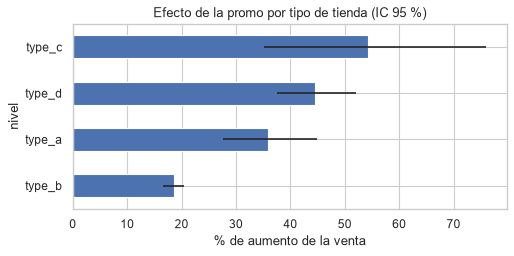

,total,type_a,type_b,type_c,type_d
promo_share,0.328,0.307,0.170,0.433,0.369
open_share,4.454,7.975,0.690,13.873,6.089
school_holiday_share,0.098,0.046,-0.028,0.125,0.177
sh_a,1.025,2.549,0.144,2.207,1.250
sh_b,0.684,2.935,0.150,0.172,0.553
sh_c,0.698,1.841,0.185,0.191,-1.192
promo2_share,-0.241,0.020,-0.145,0.066,-0.179


,total,type_a,type_b,type_c,type_d
promo_share,0.000,0.000,0.000,0.000,0.000
open_share,0.000,0.000,0.008,0.000,0.000
school_holiday_share,0.000,0.463,0.025,0.300,0.000
sh_a,0.000,0.000,0.000,0.000,0.000
sh_b,0.000,0.000,0.000,0.835,0.195
sh_c,0.000,0.015,0.000,0.865,0.065
promo2_share,0.005,0.917,0.088,0.891,0.091


In [3]:
ajustes = {u: ajustar(u, "sarimax", TEST_END) for u in ALL_LEVELS}
filas = []
for u, r in ajustes.items():
    b, ci = r.params["promo_share"], r.conf_int().loc["promo_share"]
    filas.append({"nivel": u, "β promo": b, "p-valor": r.pvalues["promo_share"], "efecto %": np.expm1(b) * 100, "IC95 inf %": np.expm1(ci.iloc[0]) * 100, "IC95 sup %": np.expm1(ci.iloc[1]) * 100})
promo = pd.DataFrame(filas).set_index("nivel"); display(promo)
tipos = promo.loc[LEVELS_TYPES].sort_values("efecto %")
ax = tipos["efecto %"].plot.barh(xerr=[tipos["efecto %"] - tipos["IC95 inf %"], tipos["IC95 sup %"] - tipos["efecto %"]], figsize=(7, 3), title="Efecto de la promo por tipo de tienda (IC 95 %)"); ax.set_xlabel("% de aumento de la venta"); plt.show()
exo = ["promo_share", "open_share", "school_holiday_share", "sh_a", "sh_b", "sh_c", "promo2_share"]
display(pd.DataFrame({u: ajustes[u].params[exo] for u in LEVELS})); display(pd.DataFrame({u: ajustes[u].pvalues[exo] for u in LEVELS}).round(4))

> **Conclusión:** manteniendo fijas las demás variables, la promoción se asocia con **+38,9 %** de venta en el total (IC 95 %: 34,9 a 43,0). Por tipo: c +54,2 % (35,1 a 76,0), d +44,6 % (37,4 a 52,1), a +36,0 % (27,6 a 44,8) y b +18,5 % (16,6 a 20,5). El tipo b responde claramente menos; entre a, c y d los intervalos se solapan, así que no se pueden ordenar con seguridad. Por tienda va de +10,2 % (`store_769`) a +97,2 % (`store_693`). Es una asociación, no un efecto causal probado, y no incluye costos ni margen. Como los residuos conservan algo de autocorrelación, los intervalos pueden ser algo estrechos.

## 3. Residuos

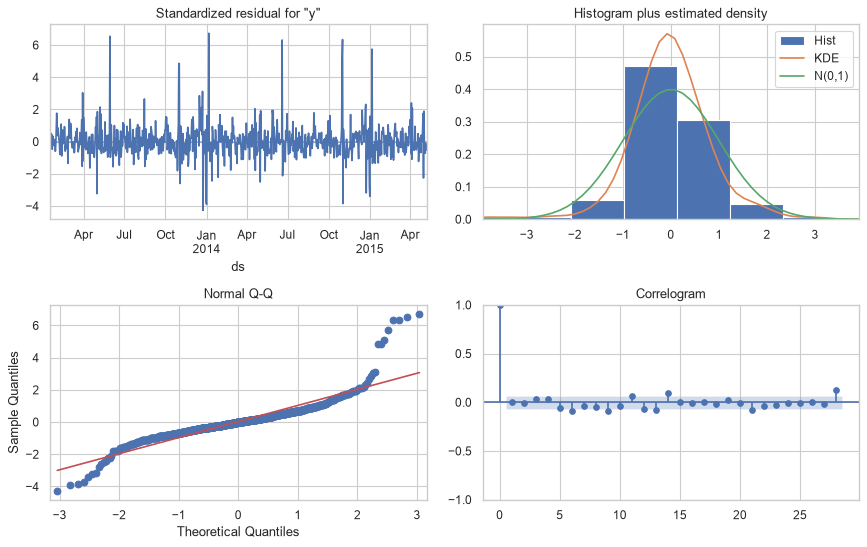

,p Ljung-Box lag 7,p Ljung-Box lag 14,p Ljung-Box lag 28
total,0.086,0.000,0.000
type_a,0.216,0.001,0.011
type_b,0.025,0.056,0.018
type_c,0.900,0.296,0.001
type_d,0.154,0.012,0.013


Días con residuo absoluto mayor (total):


,|residuo log|,fecha_dia
ds,,
2014-01-06,0.895,Monday
2013-05-30,0.872,Thursday
2014-11-01,0.844,Saturday
2014-06-19,0.840,Thursday
2015-01-06,0.765,Tuesday
2014-10-31,0.682,Friday
2013-11-01,0.647,Friday
2013-10-31,0.646,Thursday


In [4]:
res = ajustar("total", "sarimax", TRAIN_END)
fig = res.plot_diagnostics(figsize=(11, 7), lags=28); plt.tight_layout(); plt.show()
display(pd.DataFrame({u: ljung(ajustar(u, "sarimax", TRAIN_END)) for u in ["total", *LEVELS_TYPES]}).T.rename(columns=lambda k: f"p Ljung-Box lag {k}"))
r = pd.Series(res.resid).iloc[14:]; print("Días con residuo absoluto mayor (total):"); display(r.abs().nlargest(8).to_frame("|residuo log|").assign(fecha_dia=lambda d: d.index.day_name()))

> **Conclusión:** SARIMAX no elimina toda la autocorrelación: Ljung-Box rechaza en los lags 14 y 28 del total, `type_a` y `type_d`, en los lags 7 y 28 de `type_b` y en el lag 28 de `type_c`. Los mayores residuos del total caen en 06/01, 30/05/2013, 19/06/2014, 31/10 y 01/11, fechas que coinciden con festivos regionales, en los que solo cierra parte de las tiendas. El modelo es útil para pronosticar, pero sus p-valores e intervalos deben leerse con cautela.

## 4. Validación con origen móvil

AutoARIMA con exógenas, 4 ventanas de 42 días que terminan en el fin de validación. No incluye la prueba.

In [5]:
cv = pd.read_csv(ROLLING_FILE, parse_dates=["cutoff"])
print("Orígenes:", sorted(cv["cutoff"].dt.date.astype(str).unique()))
r = cv.groupby("unique_id")[["rmse", "mae", "mape"]].agg(["mean", "std"]).reindex(ALL_LEVELS); display(r)
display(cv.pivot(index="unique_id", columns="cutoff", values="mape").reindex(ALL_LEVELS))

Orígenes: ['2015-01-02', '2015-02-13', '2015-03-27', '2015-05-08']


rmse                         mae                 mape       
                   mean           std          mean           std   mean    std
unique_id                                                                      
total     1,076,381.686   452,234.524   826,252.066   427,935.415 12.274  6.416
type_a    1,112,047.653   401,160.878   815,032.654   314,684.713 50.114 48.188
type_b       15,286.335     4,776.192    11,569.527     3,391.762  6.294  1.721
type_c      199,979.707    48,260.691   139,042.931    38,366.117 16.018  5.110
type_d    1,451,021.665 1,189,305.617 1,157,484.714 1,005,381.826 61.942 46.143
store_9         898.817       154.875       609.500       132.445  9.356  2.183
store_769     1,385.888       332.722     1,099.089       302.369  9.074  2.689
store_504     1,111.044       225.745       720.151        84.838 11.569  0.618
store_960     1,029.446       285.154       739.188       164.296 12.573  2.215
store_693     1,361.736       236.652       852.710       120.539 13.788  1.871

cutoff,2015-01-02,2015-02-13,2015-03-27,2015-05-08
unique_id,,,,
total,21.531,6.761,9.955,10.848
type_a,24.768,18.120,121.541,36.028
type_b,4.642,6.711,8.528,5.296
type_c,23.076,13.254,11.457,16.285
type_d,123.877,29.527,70.262,24.104
store_9,11.217,6.196,9.976,10.035
store_769,6.355,12.680,9.300,7.960
store_504,11.077,11.933,12.251,11.016
store_960,10.687,14.495,14.488,10.622


> **Conclusión:** en las 4 ventanas, el MAPE medio es 12,3 % en el total (desviación 6,4), 6,3 % en `type_b`, 16,0 % en `type_c` y entre 9,1 % y 13,8 % en las 5 tiendas. `type_a` (50,1 %) y `type_d` (61,9 %) salen muy altos, con ventanas por encima del 120 %. Esta validación usa AutoARIMA **sin** el tratamiento de cierres totales de D-16, porque su implementación no admite faltantes, así que mide un modelo distinto del final y no debe leerse como su error esperado. Sí muestra que el error cambia bastante según el periodo.

## 5. Resultados por nivel, incluidas las 5 tiendas

Validación


,naive rmse,sarima rmse,sarimax rmse,naive mape,sarima mape,sarimax mape,mejora RMSE vs ingenuo %
nivel,,,,,,,
total,"2,655,513.310","2,192,460.585","738,377.921",171.152,120.417,8.895,72.195
type_a,"1,458,823.445","1,262,880.242","864,171.239",677.151,462.224,19.018,40.762
type_b,"22,815.634","20,776.078","15,850.876",9.620,8.181,5.241,30.526
type_c,"342,792.543","394,801.653","169,585.069",19.858,31.219,14.441,50.528
type_d,"863,068.704","771,205.839","340,162.704","1,396.544",987.791,17.458,60.587
store_9,"2,860.986","3,257.116",894.969,17.380,36.737,9.479,68.718
store_769,"1,480.514","1,325.567","1,280.523",9.353,7.733,7.067,13.508
store_504,"2,343.425","2,281.422",940.176,19.771,25.084,9.041,59.880
store_960,"2,886.540","2,737.918",911.404,24.200,28.319,10.383,68.426


Prueba (usada una sola vez)


,naive rmse,sarima rmse,sarimax rmse,naive mape,sarima mape,sarimax mape,mejora RMSE vs ingenuo %
nivel,,,,,,,
total,"1,775,080.153","1,734,123.029","571,129.585",17.413,17.075,6.806,67.825
type_a,"931,087.763","992,364.947","607,044.571",18.721,22.292,13.740,34.803
type_b,"22,299.084","18,846.196","9,635.770",9.792,8.508,3.549,56.788
type_c,"227,874.604","409,073.947","121,483.303",19.564,33.425,9.286,46.689
type_d,"601,578.302","600,180.556","301,056.576",20.739,19.874,11.205,49.956
store_9,"1,799.714","3,120.418",847.567,22.170,36.115,10.023,52.905
store_769,"1,567.571","1,621.133","1,277.761",10.086,11.124,7.738,18.488
store_504,"1,357.934","2,305.705","1,096.369",15.681,25.277,10.601,19.262
store_960,"2,110.659","2,686.905",719.133,28.756,29.795,8.507,65.928


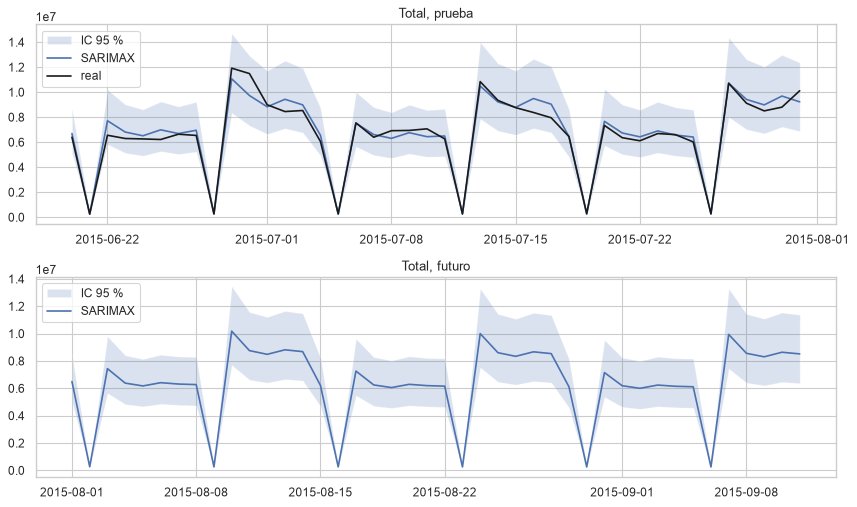

Cobertura del IC 95 % en prueba:


unique_id,total,type_a,type_b,type_c,type_d,store_9,store_769,store_504,store_960,store_693
cobertura,1.000,1.000,1.000,1.000,0.976,0.976,0.952,0.952,1.000,0.976


In [6]:
for split, nombre in [("val", "Validación"), ("test", "Prueba (usada una sola vez)")]:
    t = comparar(split)[["naive rmse", "sarima rmse", "sarimax rmse", "naive mape", "sarima mape", "sarimax mape"]]
    t["mejora RMSE vs ingenuo %"] = (1 - t["sarimax rmse"] / t["naive rmse"]) * 100; print(nombre); display(t)
fc = pd.read_parquet(ARTIFACTS / "forecasts" / "sarimax.parquet")
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5))
for ax, s in zip(axes, ["test", "future"]):
    f = fc[(fc.unique_id == "total") & (fc.split == s)]; ax.fill_between(f.ds, f.lo_95, f.hi_95, alpha=.2, label="IC 95 %"); ax.plot(f.ds, f.y_hat, label="SARIMAX")
    if s == "test": ax.plot(f.ds, f.y, "k", label="real")
    ax.set_title(f"Total, {'prueba' if s == 'test' else 'futuro'}"); ax.legend()
plt.tight_layout(); plt.show()
t = fc[fc.split == "test"]; print("Cobertura del IC 95 % en prueba:"); display(t.assign(c=(t.y >= t.lo_95) & (t.y <= t.hi_95)).groupby("unique_id")["c"].mean().reindex(ALL_LEVELS).to_frame("cobertura").T)

> **Conclusión:** SARIMAX supera al ingenuo en RMSE en los 10 niveles, tanto en validación (mejora de 13,5 % a 72,2 %) como en prueba (18,5 % a 67,8 %). En prueba el MAPE va de 3,5 % a 13,7 %, así que cumple la meta en todos los niveles. La prueba no contiene festivos, de modo que este resultado es algo favorable. La cobertura del IC 95 % va de 0,95 a 1,00: los intervalos son correctos o algo conservadores.

## 6. Modelo del simulador: carga y pronóstico como en la app

In [7]:
filas = []
for u in ALL_LEVELS:
    p = ARTIFACTS / "models" / f"sarimax_{u}.pkl"; meta = json.loads((ARTIFACTS / "models" / f"sarimax_{u}_meta.json").read_text("utf-8")); m = load_pickle(p)
    fechas = pd.date_range(FUTURE_START, FUTURE_END); X = build_future_exog(u, fechas)
    y = np.expm1(m.get_forecast(steps=len(X), exog=X[meta["exog_cols"]]).predicted_mean)
    filas.append({"nivel": u, "MB": p.stat().st_size / 1024**2, "predicciones": len(y), "finitas": bool(np.isfinite(y).all()), "venta 42 días": float(np.clip(y, 0, None).sum())})
display(pd.DataFrame(filas).set_index("nivel"))

,MB,predicciones,finitas,venta 42 días
nivel,,,,
total,0.642,42,True,"268,395,115.028"
type_a,0.655,42,True,"141,040,983.668"
type_b,0.671,42,True,"7,535,440.520"
type_c,0.661,42,True,"33,748,272.250"
type_d,0.672,42,True,"79,021,781.252"
store_9,0.651,42,True,"246,800.002"
store_769,0.661,42,True,"509,136.082"
store_504,0.651,42,True,"219,812.415"
store_960,0.642,42,True,"235,873.996"


> **Conclusión:** los 10 modelos cargan, pesan entre 0,64 y 0,67 MB y dan 42 predicciones finitas. El total proyecta 268,4 M€ y la suma de los cuatro tipos 261,3 M€, un 2,6 % menos, porque cada nivel se modela por separado y no se concilian. Este escenario usa los valores por defecto de `build_future_exog`: festivos escolares en 0 (P-07) y promoción según el patrón histórico (P-04).